# Autoregressive Text Generation on WikiText-2 (Simple RNN, BiRNN, LSTM, GRU)
**FGAI (ICT4403) Assignment 2**
Tetala Rukmender Reddy | 230911326 | Section E

I train four word-level next-word models (Simple RNN, Bidirectional RNN, LSTM and GRU) on **WikiText-2**, a standard benchmark for language modelling. All four use the same data, the same official train/validation/test split, the same layer sizes and the same training budget, so the comparison is fair. Then I compare them on loss, perplexity, accuracy and training time, and generate text from fixed seed sentences at three temperatures (0.5, 1.0, 1.5).

The notebook follows the three parts of the question:
- **Part (i)** dataset, preprocessing, sequence building, model training
- **Part (ii)** quantitative + qualitative comparison
- **Part (iii)** temperature sampling and choosing the best model

**Kaggle settings:** Accelerator = GPU (T4 or P100), Internet = On. Each model trains for up to 10 epochs with early stopping. On a Kaggle T4 the training took 70 minutes in total and the whole notebook about 75 minutes.

In [1]:
import os, re, sys, time, math, random, subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

try:
    from datasets import load_dataset
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
    from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"          # mixed precision on GPU, much faster
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
print("device:", device, torch.cuda.get_device_name(0) if USE_AMP else "", "| torch", torch.__version__)

device: cuda Tesla T4 | torch 2.11.0+cu128


---
## Part (i): Dataset, preprocessing and training

### Dataset

**WikiText-2** (Merity et al., 2016) is made from Wikipedia articles that were rated *Good* or *Featured* by editors. It was built specifically for language modelling. I use the `wikitext-2-v1` version, which is already tokenised and has rare words replaced with `<unk>`, so the vocabulary is fixed and results are comparable with other work.

- Hugging Face: https://huggingface.co/datasets/Salesforce/wikitext (config `wikitext-2-v1`)
- Paper: *Pointer Sentinel Mixture Models*, https://arxiv.org/abs/1609.07843

In [2]:
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-v1")
raw = {split: wiki[split]["text"] for split in ("train", "validation", "test")}
for split, lines in raw.items():
    print(f"{split:<11} {len(lines):>6} lines")
print()
print("".join(raw["train"][:6]))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-v1/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  685kB            

wikitext-2-v1/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

wikitext-2-v1/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 6.07MB            

wikitext-2-v1/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

...

wikitext-2-v1/validation-00000-of-00001.(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

train        36718 lines
validation    3760 lines
test          4358 lines

 = Valkyria Chronicles III = 
 Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . <unk> the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " <unk> Raven " . 
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adju

### Dataset statistics

In [3]:
HEADING = re.compile(r"^\s*(=\s)+.*(\s=)+\s*$")

def article_titles(lines):
    return [l.strip(" =\n") for l in lines if re.match(r"^ = [^=].* = \n?$", l)]

stats = {}
for split, lines in raw.items():
    words = " ".join(lines).split()
    stats[split] = {
        "articles": len(article_titles(lines)),
        "paragraphs": sum(1 for l in lines if l.strip() and not HEADING.match(l)),
        "headings": sum(1 for l in lines if HEADING.match(l)),
        "tokens": len(words),
        "unique tokens": len(set(words)),
        "<unk> share %": round(100 * words.count("<unk>") / len(words), 2),
    }
display(pd.DataFrame(stats).T)

train_words = " ".join(raw["train"]).split()
wc = Counter(train_words)
print("example article titles:", article_titles(raw["train"])[:10])
print("\n20 most common tokens:", wc.most_common(20))

,articles,paragraphs,headings,tokens,unique tokens,<unk> share %
train,629.0,17556.0,6211.0,2051910.0,33277.0,2.66
validation,60.0,1841.0,620.0,213886.0,13776.0,5.48
test,62.0,2185.0,706.0,241211.0,14142.0,6.31


example article titles: ['Valkyria Chronicles III', 'Tower Building of the Little Rock Arsenal', '<unk> Mary Barker', "Gambia women 's national football team", 'Plain maskray', '2011 – 12 Columbus Blue Jackets season', '<unk> ; <unk>', 'Goals ; A', 'Points ; <unk>', 'Games Played ; <unk>']

20 most common tokens: [('the', 113161), (',', 99913), ('.', 73388), ('of', 56889), ('<unk>', 54625), ('and', 50603), ('in', 39453), ('to', 39190), ('a', 34237), ('=', 29570), ('"', 28309), ('was', 20985), ('The', 17602), ('@-@', 16906), ('that', 14135), ('as', 14021), ("'s", 14002), ('on', 13678), ('for', 13307), ('with', 12606)]


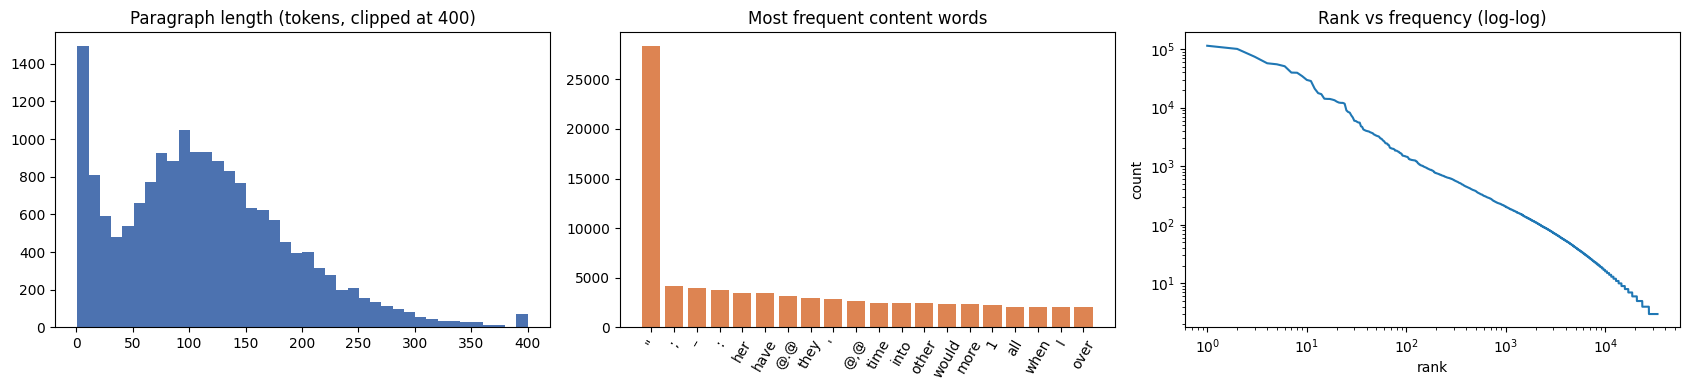

In [4]:
para_len = [len(l.split()) for l in raw["train"] if l.strip() and not HEADING.match(l)]
stop = set("the , . of and in to a was @-@ <unk> = 's for on as that with by '' `` is at from his it he an were ( ) which be this had are first also but after their one its not or two new has been who".split())
top = [(w, c) for w, c in wc.most_common(300) if w.lower() not in stop][:20]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(np.clip(para_len, 0, 400), bins=40, color="#4c72b0")
ax[0].set_title("Paragraph length (tokens, clipped at 400)")
ax[1].bar([w for w, _ in top], [c for _, c in top], color="#dd8452")
ax[1].set_title("Most frequent content words")
ax[1].tick_params(axis="x", rotation=60)
freqs = sorted(wc.values(), reverse=True)
ax[2].loglog(range(1, len(freqs) + 1), freqs)
ax[2].set_title("Rank vs frequency (log-log)")
ax[2].set_xlabel("rank"); ax[2].set_ylabel("count")
plt.tight_layout()
plt.savefig(f"{OUT}/dataset_stats.png", dpi=120)
plt.show()

**Dataset characteristics.** The training split has about 2.05 million tokens in 17,556 paragraphs from roughly 600 Wikipedia articles, and the validation and test splits are separate articles with about 214k and 241k tokens. The vocabulary is fixed at 33,278 types (33,231 of them still appear once the heading lines are removed). `<unk>` stands in for any word that appeared fewer than 3 times in the original corpus and makes up 2.7% of training tokens (5 to 6% of validation and test, because those articles contain names the training set never saw). The text keeps case, numbers and punctuation. Hyphens and number separators are written as special tokens (`@-@`, `@,@`, `@.@`), and section headings appear as lines like `= = Reception = =`.

The articles cover a huge range of topics: video games, albums and songs, warships and battles, hurricanes, sports seasons, biology and more. Paragraphs are long (apart from short one-line paragraphs, the histogram peaks around 100 tokens), and the frequency curve is the usual Zipf shape with a very long tail of rare names. The content-word chart above still shows a few punctuation tokens (quote marks, semicolons, dashes) because my stop list only removed the most common ones, but it gives an idea of how much of the text is function words and punctuation. All of this makes WikiText-2 a much harder next-word task than a single novel or a formulaic text: the next word often depends on facts (a date, a name, a chart position) that no small model can know.

### Preprocessing and input-target sequences

1. Drop empty lines and heading lines (`= Title =`, `= = Section = =`). They are structure markers, not running text.
2. Split each remaining paragraph on whitespace (the dataset is already tokenised) and add an `<eos>` token at the end of every paragraph, so the model learns where paragraphs end.
3. Build the vocabulary from the training split. The dataset is already `<unk>`-ed, so nothing else needs to be removed.
4. **Sequences:** a sliding window over each split's token stream. The previous `SEQ_LEN = 20` tokens are the input and the next token is the target (stride 1). Train, validation and test come from different articles (the official split), so there is no overlap between them.

In [5]:
def to_tokens(lines):
    out = []
    for l in lines:
        if l.strip() and not HEADING.match(l):
            out.extend(l.split() + ["<eos>"])
    return out

tokens = {split: to_tokens(lines) for split, lines in raw.items()}

itos = sorted(set(tokens["train"]))
stoi = {w: i for i, w in enumerate(itos)}
UNK, EOS = stoi["<unk>"], stoi["<eos>"]
V = len(itos)
ids = {s: np.array([stoi.get(t, UNK) for t in toks], dtype=np.int64) for s, toks in tokens.items()}

for s in ids:
    print(f"{s:<11} {len(ids[s]):>9,} tokens | <unk> {100 * (ids[s] == UNK).mean():.2f}%")
print("vocab size:", V)

train       2,024,702 tokens | <unk> 2.66%
validation    211,179 tokens | <unk> 5.46%
test          238,039 tokens | <unk> 6.28%
vocab size: 33231


In [6]:
SEQ_LEN = 20

def make_pairs(arr, n=SEQ_LEN):
    w = np.lib.stride_tricks.sliding_window_view(arr, n + 1)
    return torch.from_numpy(w[:, :-1].copy()), torch.from_numpy(w[:, -1].copy())

data = {s: make_pairs(ids[s]) for s in ids}
for s, (X, y) in data.items():
    print(f"{s:<11} X {tuple(X.shape)}  y {tuple(y.shape)}")

X_tr, y_tr = data["train"]
for i in [0, 1000, len(y_tr) // 2]:
    print(" ".join(itos[t] for t in X_tr[i].tolist()), "  ->  ", itos[y_tr[i].item()])

# keep everything on the GPU, it's small enough and avoids DataLoader overhead
data = {s: (X.to(device), y.to(device)) for s, (X, y) in data.items()}

train       X (2024682, 20)  y (2024682,)
validation  X (211159, 20)  y (211159,)
test        X (238019, 20)  y (238019,)
Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 )   ->   ,
by their motto , <unk> <unk> , meaning " Always Ready . " The three main characters are <unk> Kurt   ->   Irving
" <unk> " in the Periplus of the Erythraean Sea and Ptolemy . <unk> have found <unk> , <unk> ware   ->   ,


### Baselines
Two simple reference points for accuracy: always predicting the most common training token, and a bigram lookup (the token that most often followed the previous token in training).

In [7]:
tr = ids["train"]
most_common = np.bincount(tr, minlength=V).argmax()
follow = {}
for a, b in zip(tr[:-1], tr[1:]):
    follow.setdefault(a, Counter())[b] += 1
best_next = np.full(V, most_common)
for a, c in follow.items():
    best_next[a] = c.most_common(1)[0][0]

baselines = {}
for s in ("validation", "test"):
    tgt = ids[s][SEQ_LEN:]
    prev = ids[s][SEQ_LEN - 1:-1]
    baselines[(f"most frequent token ({itos[most_common]})", s)] = (tgt == most_common).mean()
    baselines[("bigram lookup", s)] = (best_next[prev] == tgt).mean()
baseline_df = pd.Series(baselines).unstack().round(4)
baseline_df

,test,validation
bigram lookup,0.1754,0.1751
most frequent token (the),0.0588,0.0597


### The four models

One class covers all four models, and only the recurrent layer changes. Embedding (256) -> dropout (0.3) -> recurrent layer (hidden 512) -> dropout -> linear layer over the 33k vocabulary.

- **Simple RNN**: plain tanh recurrence, the baseline. Gradients vanish over long contexts.
- **Bidirectional RNN**: two simple RNNs, one reading the 20-token window left to right and one right to left. The last forward state is joined with the last backward state. It only sees the context window, never the word it has to predict, so it can still be used for left-to-right generation.
- **LSTM**: input, forget and output gates plus a separate cell state, which help keep information over longer spans.
- **GRU**: a lighter gated cell (update and reset gates, no separate cell state), with fewer parameters than the LSTM.

In [8]:
class NextWordModel(nn.Module):
    def __init__(self, vocab_size, kind, emb_dim=256, hidden=512, dropout=0.3):
        super().__init__()
        self.kind = kind
        self.bi = kind == "birnn"
        rnn_cls = {"rnn": nn.RNN, "birnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.rnn = rnn_cls(emb_dim, hidden, batch_first=True, bidirectional=self.bi)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if self.bi else 1), vocab_size)

    def forward(self, x):
        out, _ = self.rnn(self.drop(self.emb(x)))
        if self.bi:
            H = out.size(-1) // 2
            h = torch.cat([out[:, -1, :H], out[:, 0, H:]], dim=1)   # fwd end + bwd end
        else:
            h = out[:, -1, :]
        return self.fc(self.drop(h))

names = {"rnn": "Simple RNN", "birnn": "Bidirectional RNN", "lstm": "LSTM", "gru": "GRU"}
for k in names:
    m = NextWordModel(V, k)
    print(f"{names[k]:<18} {sum(p.numel() for p in m.parameters()):>11,} params")

Simple RNN          25,948,879 params
Bidirectional RNN   43,357,391 params
LSTM                27,131,599 params
GRU                 26,737,359 params


### Training

Same settings for every model:
- Adam, learning rate 0.001, halved whenever validation loss stops improving
- batch size 512, cross-entropy loss, gradient clipping at 1.0, mixed precision on GPU
- 10 epochs, with early stopping if validation loss doesn't improve for 2 epochs in a row
- the weights from the epoch with the lowest validation loss are kept, and the seed is reset before each model

In [9]:
EPOCHS = 10
PATIENCE = 2
LR = 1e-3
BATCH = 512

@torch.no_grad()
def evaluate(model, X, y, bs=4096):
    model.eval()
    loss_sum, correct, top5 = 0.0, 0, 0
    for i in range(0, len(y), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(xb)
        logits = logits.float()
        loss_sum += nn.functional.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        top5 += (logits.topk(5, dim=1).indices == yb[:, None]).any(1).sum().item()
    n = len(y)
    return loss_sum / n, correct / n, top5 / n


def train_model(kind):
    torch.manual_seed(SEED)
    model = NextWordModel(V, kind).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=0)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    loss_fn = nn.CrossEntropyLoss()
    X, y = data["train"]
    Xv, yv = data["validation"]
    hist, best_val, best_state, best_ep, wait = [], float("inf"), None, 0, 0
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(y), device=device)
        tot, n, te = torch.zeros((), device=device), 0, time.time()
        for i in range(0, len(y), BATCH):
            idx = perm[i:i + BATCH]
            xb, yb = X[idx], y[idx]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                loss = loss_fn(model(xb), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            tot += loss.detach().float() * len(yb)
            n += len(yb)
        tot = tot.item()
        val_loss, val_acc, val_top5 = evaluate(model, Xv, yv)
        sched.step(val_loss)
        hist.append({"epoch": ep, "train_loss": tot / n, "val_loss": val_loss, "val_ppl": math.exp(val_loss),
                     "val_acc": val_acc, "val_top5": val_top5, "epoch_time": time.time() - te})
        print(f"  ep {ep:2d}  train {tot/n:.3f}  val {val_loss:.3f}  ppl {math.exp(val_loss):7.1f}  "
              f"acc {val_acc:.3f}  top5 {val_top5:.3f}  ({time.time() - te:.0f}s)")
        if val_loss < best_val - 1e-4:
            best_val, best_ep, wait = val_loss, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                print("  early stop")
                break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep, train_time

In [10]:
models, histories, summary = {}, {}, []
sub = torch.randperm(len(data["train"][1]), device=device)[:200_000]   # train accuracy on a 200k sample
for kind in names:
    print(names[kind])
    model, hist, best_ep, secs = train_model(kind)
    models[kind], histories[kind] = model, hist
    tr_loss, tr_acc, _ = evaluate(model, data["train"][0][sub], data["train"][1][sub])
    va_loss, va_acc, va_top5 = evaluate(model, *data["validation"])
    te_loss, te_acc, te_top5 = evaluate(model, *data["test"])
    summary.append({
        "model": names[kind],
        "params": sum(p.numel() for p in model.parameters()),
        "epochs_run": len(hist), "best_epoch": best_ep,
        "train_loss": tr_loss, "val_loss": va_loss, "test_loss": te_loss,
        "train_ppl": math.exp(tr_loss), "val_ppl": math.exp(va_loss), "test_ppl": math.exp(te_loss),
        "train_acc": tr_acc, "val_acc": va_acc, "test_acc": te_acc, "test_top5_acc": te_top5,
        "train_time_s": secs, "sec_per_epoch": secs / len(hist),
    })
    print(f"  done in {secs:.0f}s | best epoch {best_ep} | test ppl {math.exp(te_loss):.1f} | test acc {te_acc:.3f}\n")

Simple RNN
  ep  1  train 6.394  val 5.751  ppl   314.7  acc 0.179  top5 0.368  (84s)
  ep  2  train 5.820  val 5.637  ppl   280.7  acc 0.192  top5 0.383  (85s)
  ep  3  train 5.579  val 5.590  ppl   267.7  acc 0.196  top5 0.390  (85s)
  ep  4  train 5.436  val 5.589  ppl   267.5  acc 0.198  top5 0.394  (85s)
  ep  5  train 5.337  val 5.585  ppl   266.5  acc 0.202  top5 0.399  (85s)
  ep  6  train 5.267  val 5.601  ppl   270.8  acc 0.203  top5 0.399  (85s)
  ep  7  train 4.983  val 5.474  ppl   238.5  acc 0.209  top5 0.411  (85s)
  ep  8  train 4.880  val 5.470  ppl   237.4  acc 0.209  top5 0.409  (85s)
  ep  9  train 4.823  val 5.448  ppl   232.4  acc 0.210  top5 0.412  (85s)
  ep 10  train 4.777  val 5.455  ppl   233.9  acc 0.210  top5 0.411  (85s)
  done in 848s | best epoch 9 | test ppl 215.9 | test acc 0.212

Bidirectional RNN
  ep  1  train 6.514  val 5.912  ppl   369.5  acc 0.171  top5 0.360  (140s)
  ep  2  train 5.940  val 5.869  ppl   353.9  acc 0.187  top5 0.377  (140s)
  ep

---
## Part (ii): Comparing the models

### Quantitative metrics

All numbers use the best checkpoint of each model. Perplexity = `exp(cross-entropy)`, so lower is better. Accuracy is an exact next-token match, and top-5 counts a hit when the true token is among the five highest-scoring ones. The **test** columns are the final numbers (the test set is never used for any decision during training).

In [11]:
results = pd.DataFrame(summary).set_index("model")
results.round(4).to_csv(f"{OUT}/model_comparison.csv")
show_cols = ["params", "epochs_run", "best_epoch", "train_ppl", "val_ppl", "test_loss", "test_ppl",
             "train_acc", "val_acc", "test_acc", "test_top5_acc", "train_time_s", "sec_per_epoch"]
results[show_cols].style.format({"params": "{:,}", "train_ppl": "{:.1f}", "val_ppl": "{:.1f}",
    "test_loss": "{:.3f}", "test_ppl": "{:.1f}", "train_acc": "{:.3f}", "val_acc": "{:.3f}",
    "test_acc": "{:.3f}", "test_top5_acc": "{:.3f}", "train_time_s": "{:.0f}", "sec_per_epoch": "{:.1f}"})

,params,epochs_run,best_epoch,train_ppl,val_ppl,test_loss,test_ppl,train_acc,val_acc,test_acc,test_top5_acc,train_time_s,sec_per_epoch
model,,,,,,,,,,,,,
Simple RNN,"25,948,879",10,9,60.2,232.4,5.375,215.9,0.255,0.210,0.212,0.419,848,84.8
Bidirectional RNN,"43,357,391",10,10,26.5,280.9,5.555,258.6,0.341,0.211,0.214,0.416,1398,139.8
LSTM,"27,131,599",9,7,52.8,169.9,5.059,157.4,0.280,0.232,0.236,0.444,948,105.4
GRU,"26,737,359",10,9,30.3,168.3,5.064,158.2,0.325,0.232,0.234,0.443,1002,100.2


In [12]:
acc_table = pd.concat([baseline_df["test"], results["test_acc"]]).rename("test accuracy").to_frame()
acc_table.round(4)

,test accuracy
bigram lookup,0.1754
most frequent token (the),0.0588
Simple RNN,0.2118
Bidirectional RNN,0.2136
LSTM,0.2356
GRU,0.2340


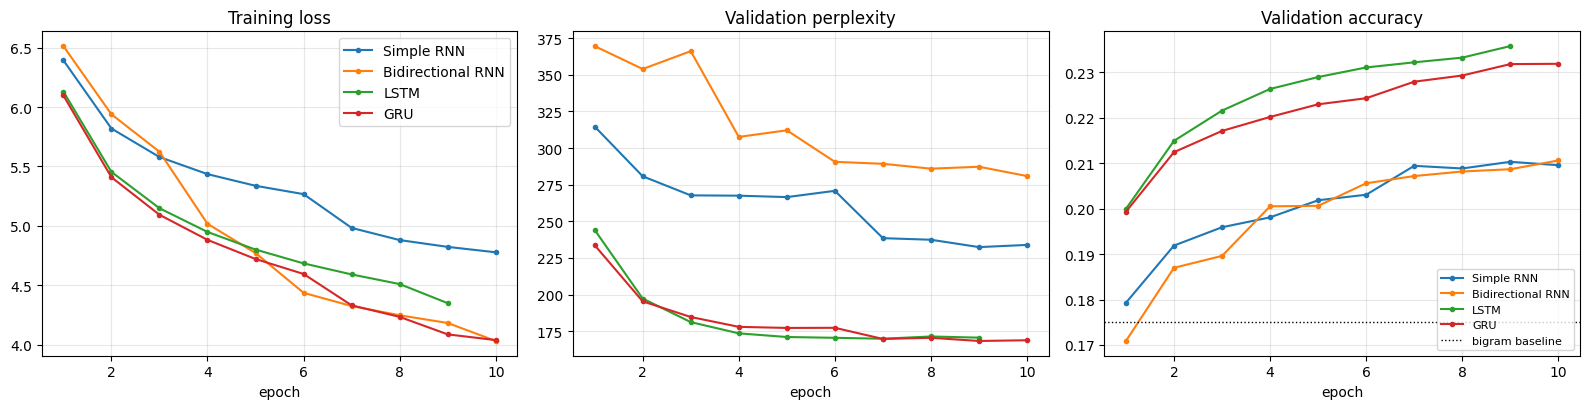

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for kind, h in histories.items():
    ax[0].plot(h.epoch, h.train_loss, marker=".", label=names[kind])
    ax[1].plot(h.epoch, h.val_ppl, marker=".", label=names[kind])
    ax[2].plot(h.epoch, h.val_acc, marker=".", label=names[kind])
ax[2].axhline(baseline_df.loc["bigram lookup", "validation"], color="k", ls=":", lw=1, label="bigram baseline")
ax[0].set_title("Training loss"); ax[1].set_title("Validation perplexity"); ax[2].set_title("Validation accuracy")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
ax[0].legend(); ax[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/training_curves.png", dpi=120)
plt.show()

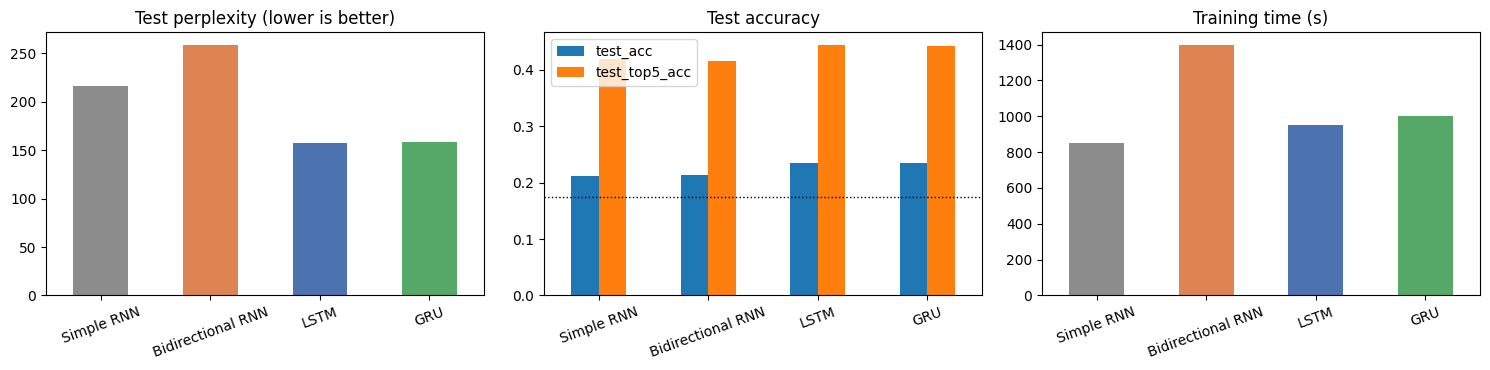

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cols = ["#8c8c8c", "#dd8452", "#4c72b0", "#55a868"]
results["test_ppl"].plot.bar(ax=ax[0], color=cols, title="Test perplexity (lower is better)")
results[["test_acc", "test_top5_acc"]].plot.bar(ax=ax[1], title="Test accuracy")
ax[1].axhline(baseline_df.loc["bigram lookup", "test"], color="k", ls=":", lw=1)
results["train_time_s"].plot.bar(ax=ax[2], color=cols, title="Training time (s)")
for a in ax:
    a.tick_params(axis="x", rotation=20); a.set_xlabel("")
plt.tight_layout()
plt.savefig(f"{OUT}/metric_bars.png", dpi=120)
plt.show()

#### Observations (quantitative)

- **LSTM** is the best model on the test set: lowest test loss (5.059) and perplexity (157.4), highest top-1 accuracy (23.6%) and highest top-5 accuracy (44.4%). The **GRU** is almost tied (perplexity 158.2, 23.4%, 44.3%) and actually had a slightly lower *validation* perplexity (168.3 vs 169.9), so the two gated models are basically level and the order between them could flip with a different seed.
- Both gated models are well ahead of the plain RNNs. Their test perplexity is about 27% lower than the Simple RNN's (215.9) and about 39% lower than the BiRNN's (258.6), and they are about 2 points better in top-1 accuracy.
- All four models beat both baselines. Guessing *the* every time gives 5.9% and the bigram lookup gives 17.5%, so the LSTM is about 6 points above the bigram model and 4 times better than the trivial guess. A top-5 accuracy of 44% means the right token is among the model's first five guesses almost half the time.
- **Overfitting.** The BiRNN has the lowest training perplexity (26.5) but the worst test perplexity (258.6), almost a 10x gap. It has the most parameters (43.4M, because its output layer takes two 512-d states), and reading the 20-token window backwards gives it more ways to memorise but no extra information about the *next* token. Its top-1 accuracy is still about the same as the Simple RNN's, but it is very overconfident when it is wrong, which is what the perplexity punishes. The LSTM has the smallest gap (train 52.8 vs test 157.4).
- **Learning rate halving helps.** The jumps in the curves at epoch 7 (Simple RNN and GRU) and epoch 4 (BiRNN) are where `ReduceLROnPlateau` halved the learning rate after a flat epoch, and validation perplexity dropped right after each one.
- **Convergence.** Only the LSTM triggered early stopping (best epoch 7, stopped at 9). The other three were still improving very slowly at epoch 10, but their curves are almost flat by then.
- **Time.** On the T4 the Simple RNN took 85 s per epoch, the GRU 100 s, the LSTM 105 s and the BiRNN 140 s. In total the four models trained for 70 minutes.
- **Context.** Test perplexity is lower than validation perplexity for all four models, so the test articles happen to be slightly easier for them. Published LSTM language models on WikiText-2 reach around 100 perplexity or lower, but they train on full sequences with long contexts and careful tuning. A single 20-token window and 10 epochs landing at 157 is in a sensible range for this setup.

### Text generation

Generation is token by token: feed the last 20 tokens, divide the logits by the temperature, softmax, sample one token, append it and repeat. `<unk>` is blocked so the text stays readable, and `<eos>` is printed as ` / ` (a paragraph break). The WikiText markers `@-@`, `@,@`, `@.@` are turned back into `-`, `,`, `.` when printing. The same three seeds are used for every model and temperature.

Text quality metrics, averaged over 5 samples per seed (15 per setting, 40 tokens each):
- **distinct-1 / distinct-2**: unique tokens / bigrams over total (diversity, higher = more varied)
- **repeated trigrams**: share of trigrams that already appeared earlier in the same sample (repetition)
- **bigram fluency PPL**: perplexity of the generated tokens under a simple bigram model of the training text, a rough local-coherence check (lower = word pairs that actually occur in Wikipedia text)
- **seed overlap**: share of the seed's content words that show up again in the continuation, a rough check of whether the text stays on the seed's topic (contextual consistency)

In [15]:
SEEDS = [
    "The game was released in North America in",
    "The album received positive reviews from music critics , who",
    "During the Second World War , the ship was",
]

def detok(toks):
    s = " ".join("/" if t == "<eos>" else t for t in toks)
    s = s.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
    return re.sub(r" ([.,;:!?)'])", r"\1", s).replace("( ", "(")

@torch.no_grad()
def generate(model, seed, n_tokens=40, temperature=1.0, greedy=False):
    model.eval()
    ctx = [stoi.get(t, UNK) for t in seed.split()]
    out = []
    for _ in range(n_tokens):
        x = torch.tensor([ctx[-SEQ_LEN:]], device=device)
        logits = model(x)[0].float()
        logits[UNK] = -float("inf")
        if greedy:
            nxt = logits.argmax().item()
        else:
            nxt = torch.multinomial(torch.softmax(logits / temperature, dim=0), 1).item()
        ctx.append(nxt)
        out.append(itos[nxt])
    return out

uni = Counter(tokens["train"])
bi = Counter(zip(tokens["train"], tokens["train"][1:]))
N = len(tokens["train"])
CONTENT_STOP = set(w.lower() for w in stop) | {"the", "a", "an", "in", "of", "to", "and", "was", "from", "who", "were", ","}

def bigram_ppl(seed, gen):
    seq = seed.split()[-1:] + gen
    lp = 0.0
    for a, b in zip(seq, seq[1:]):
        p_uni = (uni[b] + 1) / (N + V)
        p_bi = bi[(a, b)] / uni[a] if uni[a] else 0.0
        lp += math.log(0.7 * p_bi + 0.3 * p_uni)
    return math.exp(-lp / (len(seq) - 1))

def distinct(toks, n):
    grams = list(zip(*[toks[i:] for i in range(n)]))
    return len(set(grams)) / max(len(grams), 1)

def seed_overlap(seed, toks):
    content = {w.lower() for w in seed.split() if w.lower() not in CONTENT_STOP}
    gen = {w.lower() for w in toks}
    return len(content & gen) / max(len(content), 1)

def gen_stats(seed, toks):
    return {"distinct_1": distinct(toks, 1), "distinct_2": distinct(toks, 2),
            "rep_trigram": 1 - distinct(toks, 3), "bigram_ppl": bigram_ppl(seed, toks),
            "seed_overlap": seed_overlap(seed, toks)}

### Same seed, different models (greedy and T = 0.8)
Greedy decoding always takes the most likely token, which quickly shows whether a model falls into loops.

In [16]:
torch.manual_seed(7)
for seed in SEEDS:
    print("SEED:", seed)
    for kind in names:
        print(f"  [{names[kind]:<17} | greedy] ", detok(generate(models[kind], seed, 30, greedy=True)))
        print(f"  [{names[kind]:<17} | T=0.8 ] ", detok(generate(models[kind], seed, 30, 0.8)))
    print()

SEED: The game was released in North America in
  [Simple RNN        | greedy]  the United States. The album was released on September 7, 2011. The song was released on September 7, 2011. The song was released on September
  [Simple RNN        | T=0.8 ]  the United States, the House of Commons were to be held in the House of Commons. He became the work of the 1st century BCE and the 41st
  [Bidirectional RNN | greedy]  2007. / The game was released on September 21, 2008, and peaked at number one on the Billboard Hot 100. The album peaked at number one
  [Bidirectional RNN | T=0.8 ]  1990. This debuted in the video games, Roxas had released in Japan, and had a series of other Guitar Hero games. Guitar Hero Smash Hits:
  [LSTM              | greedy]  the United States, and the album was released on September 13, 2011. / The album was released on September 13, 2011, and was released on
  [LSTM              | T=0.8 ]  2010. In 1975, the 1960s was changed into the USA film. With the produci

#### Observations (qualitative)

- **Greedy decoding** loops for every model, and the loops are the most common sentence patterns in Wikipedia music and game articles. The Simple RNN repeats *"The song was released on September 7, 2011."*, the LSTM repeats *"The album was released on September 13, 2011"* and *"was the first to arrive in the Battle of Jutland"*, the BiRNN repeats song titles (*" My Happiness ", " My Happiness "*), and the GRU repeats *"The game was released in June 2015, and was released in Japan."*
- At **T = 0.8** the text has the right *style* for each seed. The game seed leads to release dates, platforms and other game titles, the album seed to reviews and chart positions, and the war seed to navies, cruisers and brigades. The GRU wrote *"scrapped on the Austro-Hungarian Navy vessel in the mid-Atlantic fleet"* and the Simple RNN wrote *"the German cruiser SMS Breslau ... launched from 1 May 1941"*.
- **Coherence** holds for a clause or two and then breaks. The gated models produce more grammatical phrases. The Simple RNN and BiRNN switch topic more abruptly (the Simple RNN goes from a game release to *"the House of Commons"* within one sentence).
- **Contextual consistency** is the main weakness for all of them. They stay in the right *domain*, but facts don't stay consistent: games *"peaked at number one on the Billboard Hot 100"*, a ship is *"commissioned by the British fleet"* and then *"by the French Navy"* in the next clause. Music and video game articles get mixed up a lot, probably because both are heavily represented in WikiText-2 and share phrases like *"was released in"*.
- **Repetition** is mostly a low-temperature problem (see Part iii). At T = 0.8 there is very little of it left.

---
## Part (iii): Effect of sampling temperature
Three temperatures for every model and seed: 0.5 (conservative), 1.0 (the model's own distribution) and 1.5 (flattened). Each combination is sampled 5 times, 40 tokens each.

In [17]:
TEMPS = [0.5, 1.0, 1.5]
torch.manual_seed(123)
rows, sample_lines = [], []
for kind in names:
    sample_lines.append(f"\n{'=' * 70}\n{names[kind]}\n{'=' * 70}")
    for T in TEMPS:
        sample_lines.append(f"\n--- temperature {T} ---")
        for seed in SEEDS:
            for k in range(5):
                toks = generate(models[kind], seed, 40, T)
                rows.append({"model": names[kind], "temperature": T, "seed": seed, **gen_stats(seed, toks)})
                if k == 0:
                    sample_lines.append(f"[{seed}] ... {detok(toks)}")

samples_text = "\n".join(sample_lines)
with open(f"{OUT}/generated_samples.txt", "w", encoding="utf-8") as f:
    f.write("Generated samples (first of 5 per seed), WikiText-2\n")
    f.write(samples_text)
print(samples_text)


Simple RNN

--- temperature 0.5 ---
[The game was released in North America in] ... the United States. The song's accompanying music video games, released on the Billboard Hot 100 chart. In the 2009 Six Nations Championship, the Tigers won a three-year-old-home dad in
[The album received positive reviews from music critics , who] ... had previously been released in the United States. In 1995, the album debuted at number 28 on September 7, 2008, and peaked at number one on the Billboard 200 chart and the album's main theme
[During the Second World War , the ship was] ... transferred to the state of the 1st Canadian Regiment, and the German cruiser Ottoman force was assigned in the Mediterranean Fleet, and began to take place on the night. / The ship was assigned to the rank

--- temperature 1.0 ---
[The game was released in North America in] ... the United States, The popular music in 2008 compilation, and Carey came on a 12 to $ one million concurrent weeks. / A large number version i

In [18]:
gen_df = pd.DataFrame(rows)
metric_cols = ["distinct_1", "distinct_2", "rep_trigram", "bigram_ppl", "seed_overlap"]
temp_table = gen_df.groupby(["model", "temperature"])[metric_cols].mean().round(3)
temp_table = temp_table.reindex(names.values(), level=0)
temp_table.to_csv(f"{OUT}/temperature_metrics.csv")
temp_table

distinct_1  distinct_2  rep_trigram  \
model             temperature                                        
Simple RNN        0.5               0.688       0.889        0.046   
                  1.0               0.865       0.998        0.000   
                  1.5               0.958       1.000        0.000   
Bidirectional RNN 0.5               0.673       0.896        0.032   
                  1.0               0.832       0.988        0.000   
                  1.5               0.925       0.997        0.000   
LSTM              0.5               0.648       0.882        0.051   
                  1.0               0.857       0.988        0.002   
                  1.5               0.955       1.000        0.000   
GRU               0.5               0.652       0.860        0.072   
                  1.0               0.837       0.993        0.000   
                  1.5               0.967       1.000        0.000   

                               bigram_ppl  seed_overlap  
model             temperature                            
Simple RNN        0.5              40.474         0.190  
                  1.0             245.106         0.063  
                  1.5            5096.286         0.041  
Bidirectional RNN 0.5              45.583         0.228  
                  1.0             231.424         0.130  
                  1.5            2658.995         0.047  
LSTM              0.5              46.705         0.091  
                  1.0             322.318         0.073  
                  1.5            6226.396         0.017  
GRU               0.5              58.327         0.253  
                  1.0             280.584         0.069  
                  1.5            7538.225         0.061

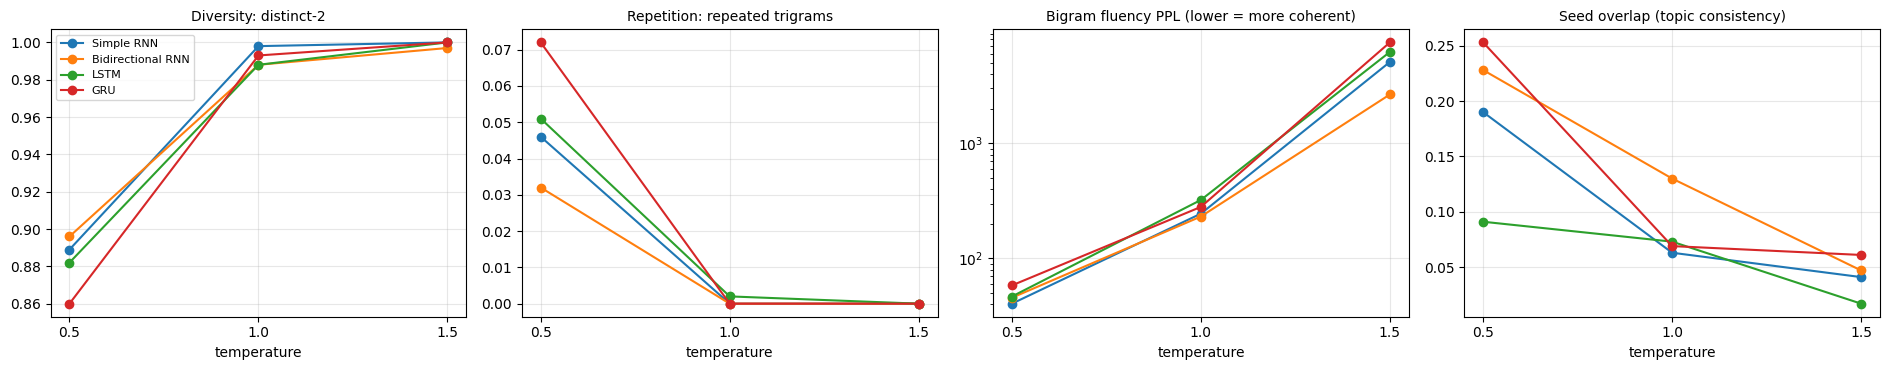

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
for (metric, title), a in zip([("distinct_2", "Diversity: distinct-2"),
                               ("rep_trigram", "Repetition: repeated trigrams"),
                               ("bigram_ppl", "Bigram fluency PPL (lower = more coherent)"),
                               ("seed_overlap", "Seed overlap (topic consistency)")], ax):
    for m in names.values():
        s = temp_table.loc[m]
        a.plot(s.index, s[metric], marker="o", label=m)
    a.set_title(title, fontsize=10); a.set_xlabel("temperature"); a.set_xticks(TEMPS); a.grid(alpha=0.3)
ax[2].set_yscale("log")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/temperature_effect.png", dpi=120)
plt.show()

#### What temperature does

| Temperature | What happens |
|---|---|
| **0.5** | The most coherent text. Bigram fluency perplexity is the lowest (about 40 to 58) and samples read like real Wikipedia sentences, for example the GRU's *"The game was released on September 25, 2011. The game was released on September 10, 2012, and was released as a digital download"*. The cost is repetition (3 to 7% of trigrams repeat inside 40 tokens) and lists (*"the 3rd Light Horse Brigade, the 2nd Light Horse Brigade, and the Anzac Mounted"*, LSTM). Content is also safe and generic: release dates, chart positions and *the Royal Navy* over and over. |
| **1.0** | Sampling from the model's actual distribution. Diversity is almost maximal (distinct-2 about 0.99) and repetition disappears, but bigram fluency perplexity is about 5 to 7 times higher (231 to 322). Text drifts off topic within a sentence, e.g. the LSTM goes from a game release to *"Telugu cinema which included Anderson's new musical release production"*, and seed overlap drops to about 0.06 to 0.13. |
| **1.5** | Word salad. Rare names and numbers get picked constantly (*"share me Nick Original links on Buffalo Yorkshire 75, 2015 Window 400 48 mobile shipments room"*, LSTM), fluency perplexity goes into the thousands (2,659 to 7,538) and almost nothing from the seed survives. |

So temperature controls the trade-off between coherence and diversity: low temperature gives fluent, safe and repetitive text, and high temperature gives varied text that loses grammar and topic. With a 33k-word vocabulary and a long tail of rare names, the distribution is very flat, so even T = 1.0 is too random here. **T around 0.5 to 0.8** gives the most usable text for this dataset.

Model differences across temperatures:
- At T = 0.5 the **BiRNN** is the most diverse (distinct-2 0.896) and least repetitive (0.032), and the **Simple RNN** has the best fluency (40.5). The **GRU** repeats the most (0.072) but has the highest seed overlap (0.253). That overlap is partly inflated by the repetition itself, because repeating *"The game was released"* keeps reusing the seed's words.
- The **LSTM** has the lowest seed overlap at 0.5 (0.091). It tends to move from the seed to a related topic (album -> song -> chart) rather than repeating the seed's words, which this simple metric counts as drift even when the text stays on topic.
- At T = 1.0 and 1.5 the BiRNN keeps the best fluency (231 and 2,659), and at T = 1.0 also the best seed overlap (0.13). That fits with it having memorised the training text the hardest. The GRU degrades the most at 1.5 (7,538).

### Run summary
This cell collects the key numbers into one table and saves everything to `results_summary.md`, so the README can be filled in straight from it.

In [20]:
def md(df):
    try:
        return df.to_markdown()
    except ImportError:            # tabulate not installed
        return "```\n" + df.to_string() + "\n```"

best_ppl = results["test_ppl"].idxmin()
best_acc = results["test_acc"].idxmax()
mid = temp_table.xs(0.5, level="temperature")
summary_md = [
    "# Run summary (WikiText-2)\n",
    f"device: {device}\n",
    "## Model comparison\n", md(results[show_cols].round(4)), "\n",
    "## Baselines (accuracy)\n", md(baseline_df), "\n",
    "## Temperature metrics\n", md(temp_table), "\n",
    f"- lowest test perplexity: **{best_ppl}** ({results.loc[best_ppl, 'test_ppl']:.1f})",
    f"- highest test accuracy: **{best_acc}** ({results.loc[best_acc, 'test_acc']:.3f})",
    f"- most diverse at T=0.5: **{mid['distinct_2'].idxmax()}**, least repetitive at T=0.5: **{mid['rep_trigram'].idxmin()}**",
    f"- total training time: {results['train_time_s'].sum() / 60:.1f} min",
]
with open(f"{OUT}/results_summary.md", "w", encoding="utf-8") as f:
    f.write("\n".join(summary_md))
print("\n".join(summary_md[-4:]))

- lowest test perplexity: **LSTM** (157.4)
- highest test accuracy: **LSTM** (0.236)
- most diverse at T=0.5: **Bidirectional RNN**, least repetitive at T=0.5: **Bidirectional RNN**
- total training time: 70.0 min


---
## Conclusion

**The LSTM is the most effective autoregressive generator for WikiText-2 in this experiment, with the GRU a very close second.**

1. It has the best held-out numbers: test loss 5.059, perplexity 157.4, top-1 accuracy 23.6% and top-5 accuracy 44.4%. That is 6 points above the bigram baseline (17.5%) and 4 times better than always guessing *the* (5.9%).
2. It generalises best, with the smallest gap between training and test perplexity (52.8 vs 157.4). It is also the only model whose validation loss stopped improving within the 10 epochs (best epoch 7), so it got the most out of the training budget.
3. It trained faster than the GRU on the T4 (948 s vs 1002 s), and its samples at T = 0.5 to 0.8 are grammatical and on the seed's general topic.

The GRU reaches practically the same perplexity and accuracy, so either gated model is a good choice. The Simple RNN is the fastest but clearly less accurate. The Bidirectional RNN is the least suitable: it has 60% more parameters, overfits the most, and its backward pass over the context can't help with predicting a token that comes *after* the context. For generation, the recommended setup is the **LSTM sampled at a temperature of about 0.5 to 0.8**. Lower temperatures loop and higher ones lose coherence quickly on a vocabulary this large.

All plots, tables and generated samples are saved in `/kaggle/working` (and in the `results/` and `samples/` folders of the repository).